In [29]:
print("My regression setup is ready!")

My regression setup is ready!


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [31]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current folder:
c:\Users\Ruchi\OneDrive\Documents\Kaggle_ML_Assignment

Files and folders here:
['.venv', 'flight-price-prediction', 'Flight_Price_Regression.ipynb']


In [32]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d != ".venv"]
    for file in files:
        print(os.path.join(root, file))

.\Flight_Price_Regression.ipynb
.\flight-price-prediction\submission.csv
.\flight-price-prediction\test.csv
.\flight-price-prediction\train.csv


In [33]:

# Import the os module to work with files and folders.
import os

# Display the folder in which Python is currently working.
print("Current working directory:")
print(os.getcwd())

# Display all files and folders present in the current directory.
print("\nFiles and folders in the current directory:")
print(os.listdir())


Current working directory:
c:\Users\Ruchi\OneDrive\Documents\Kaggle_ML_Assignment

Files and folders in the current directory:
['.venv', 'flight-price-prediction', 'Flight_Price_Regression.ipynb']


In [34]:

# Walk through the project directory and its subdirectories.
for root, dirs, files in os.walk("."):

    # Skip the virtual environment because it contains many unrelated files.
    dirs[:] = [folder for folder in dirs if folder != ".venv"]

    # Print the path of every file found in the project.
    for file in files:
        print(os.path.join(root, file))


.\Flight_Price_Regression.ipynb
.\flight-price-prediction\submission.csv
.\flight-price-prediction\test.csv
.\flight-price-prediction\train.csv


In [35]:

# Import pandas to load and work with tabular data.
import pandas as pd

# Load the training dataset used to train our machine learning models.
train = pd.read_csv("flight-price-prediction/train.csv")

# Load the test dataset on which we will generate predictions.
test = pd.read_csv("flight-price-prediction/test.csv")

# Load the sample submission file to understand Kaggle's required format.
submission = pd.read_csv("flight-price-prediction/submission.csv")

# Display the number of rows and columns in each dataset.
print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)
print("Submission dataset shape:", submission.shape)


Training dataset shape: (18076, 12)
Test dataset shape: (4520, 11)
Submission dataset shape: (4520, 2)


In [36]:

# Display the first five rows to understand the structure of the training data.
display(train.head())

# Display all column names to identify the input features and target variable.
print("Column names:")
print(train.columns.tolist())

# Display column data types and the number of non-missing values.
train.info()


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


Column names:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price']
<class 'pandas.DataFrame'>
RangeIndex: 18076 entries, 0 to 18075
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                18076 non-null  int64  
 1   airline           18076 non-null  str    
 2   flight            18076 non-null  str    
 3   source_city       18076 non-null  str    
 4   departure_time    18076 non-null  str    
 5   stops             18076 non-null  str    
 6   arrival_time      18076 non-null  str    
 7   destination_city  18076 non-null  str    
 8   flight_class      18076 non-null  str    
 9   duration          18076 non-null  float64
 10  days_left         18076 non-null  int64  
 11  price             18076 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 1.7 MB


In [37]:

# Check the number of missing values in each column.
print("Missing values in each column:")
print(train.isnull().sum())

# Count the number of completely duplicated rows.
print("\nNumber of duplicate rows:")
print(train.duplicated().sum())

# Display descriptive statistics for numerical columns.
print("\nStatistical summary of numerical columns:")
display(train.describe())

# Check how many unique values each column contains.
print("\nNumber of unique values in each column:")
print(train.nunique())


Missing values in each column:
id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
price               0
dtype: int64

Number of duplicate rows:
0

Statistical summary of numerical columns:


,id,duration,days_left,price
count,18076.000000,18076.000000,18076.000000,18076.000000
mean,11308.626189,2.746853,20.520912,280.264550
std,6526.337957,2.947519,12.094984,221.965133
min,0.000000,0.870000,1.000000,0.000000
25%,5668.750000,1.470000,10.000000,157.000000
50%,11329.500000,1.630000,20.000000,234.000000
75%,16949.500000,2.000000,31.000000,336.000000
max,22595.000000,28.650000,44.000000,8996.000000



Number of unique values in each column:
id                  18076
airline                 7
flight               1123
source_city             5
departure_time          6
stops                   3
arrival_time            6
destination_city        5
flight_class            2
duration              576
days_left              44
price                 768
dtype: int64


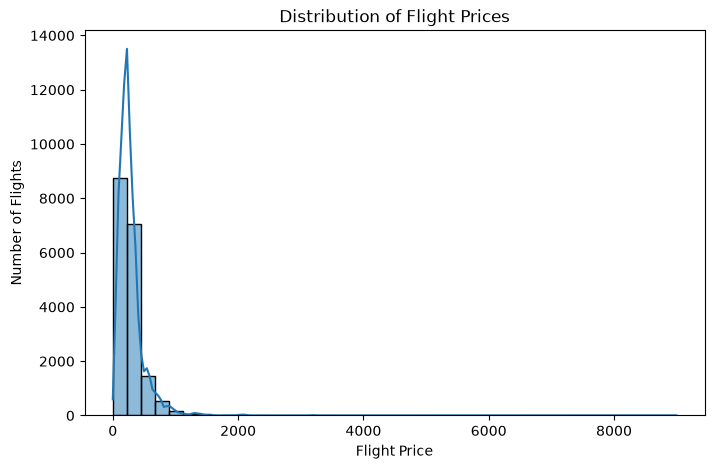

In [38]:

# Create a histogram to understand the distribution of flight prices.
plt.figure(figsize=(8, 5))

# Plot the frequency of different ticket prices.
sns.histplot(data=train, x="price", bins=40, kde=True)

# Add a title and labels to make the chart easy to interpret.
plt.title("Distribution of Flight Prices")
plt.xlabel("Flight Price")
plt.ylabel("Number of Flights")

# Display the chart.
plt.show()


In [39]:

# Display the distinct categories present in important categorical columns.
categorical_columns = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

# Print the categories found in each selected column.
for column in categorical_columns:
    print(f"\n{column}:")
    print(train[column].value_counts())



airline:
airline
Alaska_Airlines             4554
United                      4058
Southwest                   3895
Delta                       2972
American_Airlines           1797
Frontier                     799
Southern_Airways_Express       1
Name: count, dtype: int64

source_city:
source_city
Los Angeles      4561
San Francisco    4086
San Diego        3691
Sacramento       3521
San Jose         2217
Name: count, dtype: int64

departure_time:
departure_time
Morning          5144
Evening          4436
Afternoon        3893
Early_Morning    2820
Night            1777
Late_Night          6
Name: count, dtype: int64

stops:
stops
zero           13559
one             4324
two_or_more      193
Name: count, dtype: int64

arrival_time:
arrival_time
Afternoon        4785
Evening          4549
Morning          4364
Night            3701
Early_Morning     525
Late_Night        152
Name: count, dtype: int64

destination_city:
destination_city
Los Angeles      4533
San Francisco    4073
San 

In [40]:
# Separate the target column that the model must predict.
y = train["price"]

# Remove the target column from the input features.
X = train.drop(columns=["price"])

# Display the dimensions of the features and target.
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display the first five rows of the input features.
display(X.head())

Features shape: (18076, 11)
Target shape: (18076,)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9


In [41]:
# Import the function used to split data into training and validation sets.
from sklearn.model_selection import train_test_split

# Split the features and target using an 80:20 ratio.
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Print the number of rows assigned to each set.
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (14460, 11)
Validation features: (3616, 11)
Training target: (14460,)
Validation target: (3616,)


In [42]:
# Import tools for preprocessing categorical and numerical features.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify columns that contain text categories.
categorical_columns = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Identify columns that contain numerical values.
numerical_columns = X.select_dtypes(include=["number"]).columns.tolist()

# One-hot encode categorical columns and scale numerical columns.
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", StandardScaler(), numerical_columns)
    ]
)

# Learn preprocessing rules from training data and transform the training features.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same learned preprocessing rules to validation features.
X_val_processed = preprocessor.transform(X_val)

# Display the dimensions after preprocessing.
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

Processed training shape: (14460, 1113)
Processed validation shape: (3616, 1113)


In [43]:
# Import the Linear Regression model and evaluation metrics.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a standard Linear Regression model.
lr_model = LinearRegression()

# Train the model using the processed training data.
lr_model.fit(X_train_processed, y_train)

# Predict flight prices for the unseen validation data.
lr_predictions = lr_model.predict(X_val_processed)

# Calculate the mean absolute prediction error.
lr_mae = mean_absolute_error(y_val, lr_predictions)

# Calculate the root mean squared prediction error.
lr_rmse = np.sqrt(mean_squared_error(y_val, lr_predictions))

# Calculate the coefficient of determination.
lr_r2 = r2_score(y_val, lr_predictions)

# Display the evaluation results.
print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("R² Score:", round(lr_r2, 4))

Linear Regression Results
-------------------------
MAE: 75.78
RMSE: 163.08
R² Score: 0.5272


In [44]:
# Import Ridge Regression from scikit-learn.
from sklearn.linear_model import Ridge

# Create a Ridge model with a regularization strength of 1.0.
ridge_model = Ridge(alpha=1.0)

# Train Ridge Regression on the preprocessed training data.
ridge_model.fit(X_train_processed, y_train)

# Predict prices for the validation data.
ridge_predictions = ridge_model.predict(X_val_processed)

# Calculate the mean absolute error.
ridge_mae = mean_absolute_error(y_val, ridge_predictions)

# Calculate the root mean squared error.
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))

# Calculate the R-squared score.
ridge_r2 = r2_score(y_val, ridge_predictions)

# Display the evaluation metrics.
print("Ridge Regression Results")
print("------------------------")
print("MAE:", round(ridge_mae, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R² Score:", round(ridge_r2, 4))

Ridge Regression Results
------------------------
MAE: 75.86
RMSE: 162.86
R² Score: 0.5285


In [45]:
# Import Lasso Regression from scikit-learn.
from sklearn.linear_model import Lasso

# Create a Lasso model with a regularization strength of 1.0.
lasso_model = Lasso(alpha=1.0, max_iter=10000)

# Train Lasso Regression on the preprocessed training data.
lasso_model.fit(X_train_processed, y_train)

# Predict prices for the validation data.
lasso_predictions = lasso_model.predict(X_val_processed)

# Calculate the mean absolute error.
lasso_mae = mean_absolute_error(y_val, lasso_predictions)

# Calculate the root mean squared error.
lasso_rmse = np.sqrt(mean_squared_error(y_val, lasso_predictions))

# Calculate the R-squared score.
lasso_r2 = r2_score(y_val, lasso_predictions)

# Display the evaluation metrics.
print("Lasso Regression Results")
print("------------------------")
print("MAE:", round(lasso_mae, 2))
print("RMSE:", round(lasso_rmse, 2))
print("R² Score:", round(lasso_r2, 4))

Lasso Regression Results
------------------------
MAE: 91.77
RMSE: 180.18
R² Score: 0.4229


In [46]:
# Store the evaluation metrics for all three trained models.
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "MAE": [lr_mae, ridge_mae, lasso_mae],
    "RMSE": [lr_rmse, ridge_rmse, lasso_rmse],
    "R2 Score": [lr_r2, ridge_r2, lasso_r2]
})

# Sort models by MAE, placing the lowest-error model first.
results = results.sort_values(by="MAE", ascending=True)

# Display the comparison table with rounded metric values.
display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,75.7764,163.0832,0.5272
1,Ridge Regression,75.8633,162.8565,0.5285
2,Lasso Regression,91.7652,180.1756,0.4229


In [47]:
# Import PolynomialFeatures to generate polynomial and interaction features.
from sklearn.preprocessing import PolynomialFeatures

# Import LinearRegression to train the polynomial regression model.
from sklearn.linear_model import LinearRegression

# Create degree-2 polynomial features without adding a separate bias column.
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)

# Fit the polynomial transformation on training data and transform it.
X_train_poly = poly_transformer.fit_transform(X_train_processed)

# Apply the same polynomial transformation to validation data.
X_val_poly = poly_transformer.transform(X_val_processed)

# Display the feature counts before and after polynomial expansion.
print("Features before polynomial expansion:", X_train_processed.shape[1])
print("Features after polynomial expansion:", X_train_poly.shape[1])

# Create the Linear Regression model for polynomial features.
poly_model = LinearRegression()

# Train the model on the expanded training features.
poly_model.fit(X_train_poly, y_train)

# Predict flight prices using the expanded validation features.
poly_predictions = poly_model.predict(X_val_poly)

# Calculate the mean absolute prediction error.
poly_mae = mean_absolute_error(y_val, poly_predictions)

# Calculate the root mean squared prediction error.
poly_rmse = np.sqrt(mean_squared_error(y_val, poly_predictions))

# Calculate the R-squared score.
poly_r2 = r2_score(y_val, poly_predictions)

# Print the evaluation metrics.
print("\nPolynomial Regression Results")
print("-----------------------------")
print("MAE:", round(poly_mae, 2))
print("RMSE:", round(poly_rmse, 2))
print("R² Score:", round(poly_r2, 4))

Features before polynomial expansion: 1113
Features after polynomial expansion: 621054

Polynomial Regression Results
-----------------------------
MAE: 109.75
RMSE: 444.34
R² Score: -2.5097


In [48]:
# Collect the evaluation metrics from all four regression models.
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Polynomial Regression (degree 2)"
    ],
    "MAE": [lr_mae, ridge_mae, lasso_mae, poly_mae],
    "RMSE": [lr_rmse, ridge_rmse, lasso_rmse, poly_rmse],
    "R2 Score": [lr_r2, ridge_r2, lasso_r2, poly_r2]
})

# Sort models by MAE so the lowest average absolute error appears first.
results = results.sort_values(by="MAE", ascending=True)

# Display the comparison table rounded to four decimal places.
display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,75.7764,163.0832,0.5272
1,Ridge Regression,75.8633,162.8565,0.5285
2,Lasso Regression,91.7652,180.1756,0.4229
3,Polynomial Regression (degree 2),109.7550,444.3426,-2.5097


In [49]:
# Import tools for numerical polynomial features and model preprocessing.
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Select the numerical columns for polynomial expansion.
numeric_features = ["duration", "days_left"]

# Select the categorical columns for one-hot encoding.
categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Create degree-2 polynomial terms only for the selected numerical columns.
numeric_pipeline = Pipeline([
    # Generate squared terms and interactions between numerical features.
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    # Scale polynomial features to help regularization work more consistently.
    ("scaler", StandardScaler())
])

# One-hot encode categories without creating polynomial combinations of them.
categorical_pipeline = OneHotEncoder(handle_unknown="ignore")

# Apply separate transformations to numerical and categorical features.
poly_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build a complete model that preprocesses features and applies Ridge Regression.
poly_ridge_model = Pipeline([
    ("preprocessor", poly_preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

# Train the model using the original training DataFrame.
poly_ridge_model.fit(X_train, y_train)

# Predict prices for the original validation DataFrame.
poly_ridge_predictions = poly_ridge_model.predict(X_val)

# Calculate the mean absolute error.
poly_ridge_mae = mean_absolute_error(y_val, poly_ridge_predictions)

# Calculate the root mean squared error.
poly_ridge_rmse = np.sqrt(mean_squared_error(y_val, poly_ridge_predictions))

# Calculate the R-squared score.
poly_ridge_r2 = r2_score(y_val, poly_ridge_predictions)

# Display the evaluation results.
print("Polynomial Features + Ridge Regression")
print("---------------------------------------")
print("MAE:", round(poly_ridge_mae, 2))
print("RMSE:", round(poly_ridge_rmse, 2))
print("R² Score:", round(poly_ridge_r2, 4))

Polynomial Features + Ridge Regression
---------------------------------------
MAE: 77.63
RMSE: 164.72
R² Score: 0.5177


In [50]:

# Import Pipeline to combine preprocessing and model training into one workflow.
from sklearn.pipeline import Pipeline

# Import ColumnTransformer to apply different preprocessing to numerical and categorical columns.
from sklearn.compose import ColumnTransformer

# Import OneHotEncoder to convert categorical text values into numerical features.
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Import Ridge Regression, which adds an L2 penalty to reduce excessively large coefficients.
from sklearn.linear_model import Ridge

# Import GridSearchCV to test multiple hyperparameter values using cross-validation.
from sklearn.model_selection import GridSearchCV

# Import evaluation metrics to measure the model's prediction performance.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Identify categorical columns because machine learning models cannot directly use text categories.
categorical_columns = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Identify numerical columns because they need numerical preprocessing rather than one-hot encoding.
numerical_columns = X.select_dtypes(include=["number"]).columns.tolist()

# Create a preprocessing step that one-hot encodes categories and scales numerical features.
# We use handle_unknown="ignore" so unseen categories do not cause errors during validation.
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", StandardScaler(), numerical_columns)
    ]
)

# Combine preprocessing and Ridge Regression into one pipeline.
# This makes sure preprocessing is fitted only on the training portion of each CV fold.
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Define the alpha values we want to compare.
# Alpha controls the strength of Ridge's penalty: larger values mean stronger regularization.
ridge_parameters = {
    "regressor__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Set up a five-fold grid search to compare the candidate alpha values.
# Negative MAE is used because scikit-learn maximizes scores, while lower MAE is better.
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_parameters,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

# Train and compare the candidate models using only the training dataset.
# The validation dataset remains untouched until we evaluate the selected model.
ridge_search.fit(X_train, y_train)

# Display the alpha value that achieved the best average cross-validation MAE.
print("Best Ridge alpha:", ridge_search.best_params_["regressor__alpha"])

# Convert the negative cross-validation score into a positive MAE for easier interpretation.
print("Best CV MAE:", round(-ridge_search.best_score_, 2))

# Retrieve the complete pipeline with the best alpha selected by grid search.
best_ridge_model = ridge_search.best_estimator_

# Predict prices for the validation dataset using the selected pipeline.
# The pipeline automatically applies the same learned preprocessing before predicting.
best_ridge_predictions = best_ridge_model.predict(X_val)

# Calculate the average absolute difference between actual and predicted prices.
best_ridge_mae = mean_absolute_error(y_val, best_ridge_predictions)

# Calculate RMSE, which penalizes larger prediction errors more strongly.
best_ridge_rmse = np.sqrt(mean_squared_error(y_val, best_ridge_predictions))

# Calculate R-squared to measure how much variation in prices the model explains.
best_ridge_r2 = r2_score(y_val, best_ridge_predictions)

# Display all three validation metrics to compare this model with our earlier experiments.
print("\nTuned Ridge Validation Results")
print("MAE:", round(best_ridge_mae, 2))
print("RMSE:", round(best_ridge_rmse, 2))
print("R² Score:", round(best_ridge_r2, 4))


Best Ridge alpha: 1.0
Best CV MAE: 71.46

Tuned Ridge Validation Results
MAE: 75.86
RMSE: 162.86
R² Score: 0.5285


In [51]:

# Import the model, preprocessing tools, and evaluation metrics needed for comparison.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define the original feature set and a version without identifier-like columns.
# We remove id and flight in the second experiment to test whether they help prediction.
feature_sets = {
    "All features": X_train.columns.tolist(),
    "Without id and flight": [
        column for column in X_train.columns
        if column not in ["id", "flight"]
    ]
}

# Store the validation results from each experiment for easy comparison.
feature_results = []

# Train and evaluate one Ridge model for each feature set.
for experiment_name, selected_columns in feature_sets.items():

    # Separate categorical and numerical columns using only the selected features.
    categorical_columns = X_train[selected_columns].select_dtypes(
        include=["object", "str"]
    ).columns.tolist()

    numerical_columns = X_train[selected_columns].select_dtypes(
        include=["number"]
    ).columns.tolist()

    # Encode categorical values and scale numerical values.
    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", StandardScaler(), numerical_columns)
    ])

    # Combine preprocessing and Ridge Regression into a single pipeline.
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0))
    ])

    # Train the model using the selected training features.
    model.fit(X_train[selected_columns], y_train)

    # Predict prices for the same held-out validation examples.
    predictions = model.predict(X_val[selected_columns])

    # Calculate validation metrics to compare the two feature sets fairly.
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    # Save the metrics with the experiment name.
    feature_results.append({
        "Experiment": experiment_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Display the results side by side, with errors rounded for readability.
feature_comparison = pd.DataFrame(feature_results)
print(feature_comparison.round(4).to_string(index=False))


           Experiment     MAE     RMSE     R2
         All features 75.8633 162.8565 0.5285
Without id and flight 93.7734 182.1384 0.4103


In [52]:

# Import the tools needed to preprocess features and evaluate Ridge Regression.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define three experiments to measure the individual contribution of id and flight.
feature_experiments = {
    "All features": X_train.columns.tolist(),
    "Without id": [c for c in X_train.columns if c != "id"],
    "Without flight": [c for c in X_train.columns if c != "flight"]
}

# Create a list to collect the validation metrics from each experiment.
results = []

# Train and evaluate a separate Ridge model for each feature selection.
for experiment_name, columns in feature_experiments.items():

    # Identify categorical columns that need one-hot encoding.
    categorical_columns = X_train[columns].select_dtypes(
        include=["object", "str"]
    ).columns.tolist()

    # Identify numerical columns that need scaling.
    numerical_columns = X_train[columns].select_dtypes(
        include=["number"]
    ).columns.tolist()

    # Build preprocessing that handles categories and numbers separately.
    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", StandardScaler(), numerical_columns)
    ])

    # Create a pipeline so preprocessing and Ridge Regression run together.
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0))
    ])

    # Fit the model on the training data using only the selected columns.
    model.fit(X_train[columns], y_train)

    # Predict prices for the same validation examples in every experiment.
    predictions = model.predict(X_val[columns])

    # Calculate the mean absolute prediction error.
    mae = mean_absolute_error(y_val, predictions)

    # Calculate root mean squared error to penalize large mistakes more strongly.
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    # Calculate R-squared to assess how much price variation the model explains.
    r2 = r2_score(y_val, predictions)

    # Save the experiment name and its evaluation metrics.
    results.append({
        "Experiment": experiment_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Display the results side by side to identify the best feature selection.
print(pd.DataFrame(results).round(4).to_string(index=False))


    Experiment     MAE     RMSE     R2
  All features 75.8633 162.8565 0.5285
    Without id 75.7779 162.9842 0.5278
Without flight 93.7235 181.9171 0.4117


In [53]:

# Create a table containing the validation results of all regression experiments.
# These values let us compare models without relying on memory or separate outputs.
model_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": lr_mae,
        "RMSE": lr_rmse,
        "R2": lr_r2
    },
    {
        "Model": "Ridge Regression",
        "MAE": best_ridge_mae,
        "RMSE": best_ridge_rmse,
        "R2": best_ridge_r2
    },
    {
        "Model": "Lasso Regression",
        "MAE": 91.7652,
        "RMSE": 180.1756,
        "R2": 0.4229
    },
    {
        "Model": "Polynomial Regression",
        "MAE": 109.7550,
        "RMSE": 444.3426,
        "R2": -2.5097
    },
    {
        "Model": "Polynomial + Ridge",
        "MAE": poly_ridge_mae,
        "RMSE": poly_ridge_rmse,
        "R2": poly_ridge_r2
    }
])

# Sort models by MAE so the model with the lowest absolute prediction error appears first.
model_comparison = model_comparison.sort_values(by="MAE")

# Round the displayed metrics to make the comparison easier to read.
display(model_comparison.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,75.7764,163.0832,0.5272
1,Ridge Regression,75.8633,162.8565,0.5285
4,Polynomial + Ridge,77.6263,164.7228,0.5177
2,Lasso Regression,91.7652,180.1756,0.4229
3,Polynomial Regression,109.7550,444.3426,-2.5097


## Conclusion

Five regression approaches were evaluated for the flight price prediction task: Linear Regression, Ridge Regression, Lasso Regression, Polynomial Regression, and Polynomial Features combined with Ridge Regression.

Linear Regression achieved the lowest validation MAE of 75.7764, while Ridge Regression achieved the lowest RMSE of 162.8565 and the highest R² score of 0.5285. The difference between the two models was small, indicating that regularization provided only a marginal improvement for this dataset.

Lasso Regression performed worse than Linear and Ridge Regression with the selected regularization strength. Polynomial Regression performed poorly, with a negative R² score, while combining polynomial features with Ridge Regression improved the results but did not outperform the simpler models.

Feature experiments showed that removing the `flight` column substantially reduced performance, whereas removing `id` had only a minor effect. These observations suggest that feature selection and model complexity influence predictive performance.

Overall, Linear Regression and Ridge Regression were the strongest models among the approaches tested. Further improvements may be possible through feature engineering, hyperparameter tuning, and comparison with tree-based regression models.

In [54]:

# Display the column names and first few rows of the sample submission file.
# Kaggle requires the final prediction file to follow this exact column structure.
print("Sample submission columns:")
print(submission.columns.tolist())

# Display example rows to identify the prediction column and required ID format.
display(submission.head())

# Check the columns available in the test dataset.
# This helps us verify that the test features match the model's expected inputs.
print("Test dataset columns:")
print(test.columns.tolist())

# Display the first few test examples to inspect their structure.
display(test.head())


Sample submission columns:
['id', 'price']


,id,price
0,18395,18395
1,11771,11771
2,22326,22326
3,18332,18332
4,11021,11021


Test dataset columns:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,18395,Southwest,WN 2981,San Francisco,Morning,zero,Afternoon,San Diego,Economy,1.67,32
1,11771,Southwest,WN 2526,Los Angeles,Night,zero,Night,San Jose,Economy,1.17,19
2,22326,Alaska_Airlines,AS 3359,San Jose,Morning,one,Evening,Sacramento,Business,6.13,44
3,18332,Southwest,WN 2462,San Jose,Afternoon,zero,Afternoon,Los Angeles,Economy,1.33,26
4,11021,American_Airlines,AA 6279,Sacramento,Morning,one,Afternoon,San Francisco,Economy,3.87,19


In [55]:

# Import the tools required to preprocess the data and train the final Ridge model.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
import pandas as pd

# Separate the target prices from the complete labelled training dataset.
# We need these known prices to train the final model on all available training rows.
X_full = train.drop(columns=["price"])
y_full = train["price"]

# Identify categorical columns that contain text values.
categorical_columns = X_full.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Identify numerical columns that contain numeric values.
numerical_columns = X_full.select_dtypes(
    include=["number"]
).columns.tolist()

# Create preprocessing that encodes categories and scales numerical features.
# handle_unknown="ignore" allows the model to process categories not seen during training.
final_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ("numerical", StandardScaler(), numerical_columns)
])

# Combine preprocessing and Ridge Regression into one pipeline.
# This ensures that the same preprocessing steps are applied to training and test data.
final_model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

# Train the final model using every labelled row in train.csv.
# We use all available labelled data after completing our validation experiments.
final_model.fit(X_full, y_full)

# Predict prices for the rows in test.csv, which does not contain the actual prices.
test_predictions = final_model.predict(test)

# Load the sample submission again to preserve Kaggle's required column order and format.
final_submission = pd.read_csv(
    "flight-price-prediction/submission.csv"
)

# Replace the sample's placeholder prices with our model's predicted prices.
# Keep the sample's ID column unchanged so every prediction matches the correct row.
final_submission["price"] = test_predictions

# Save the completed predictions as a new CSV file without adding an extra index column.
final_submission.to_csv(
    "flight-price-prediction/ridge_submission.csv",
    index=False
)

# Display the first few predictions to check that the file looks correct.
display(final_submission.head())

# Print the output location so we know where the submission file was saved.
print("Submission saved to: flight-price-prediction/ridge_submission.csv")

# Check that the number of predictions matches the number of test rows.
print("Number of test rows:", len(test))
print("Number of predictions:", len(test_predictions))

# Confirm that the saved submission has the required columns.
print("Submission columns:", final_submission.columns.tolist())


,id,price
0,18395,52.430197
1,11771,157.091663
2,22326,404.115714
3,18332,117.158893
4,11021,372.046942


Submission saved to: flight-price-prediction/ridge_submission.csv
Number of test rows: 4520
Number of predictions: 4520
Submission columns: ['id', 'price']


In [56]:

# Reload the saved CSV to verify the actual file rather than relying on notebook display formatting.
check_submission = pd.read_csv(
    "flight-price-prediction/ridge_submission.csv"
)

# Print the column names and shape to confirm that the file has exactly two columns.
print("Columns:", check_submission.columns.tolist())
print("Shape:", check_submission.shape)

# Display the first five rows to check that predicted prices replaced the sample placeholders.
display(check_submission.head())

# Check whether any predicted prices are missing or non-finite.
print(
    "Missing prices:",
    check_submission["price"].isna().sum()
)
print(
    "Finite prices:",
    np.isfinite(check_submission["price"]).all()
)

# Check that IDs in the submission match the IDs in the test dataset in the same order.
print(
    "IDs match test data:",
    check_submission["id"].equals(test["id"])
)


Columns: ['id', 'price']
Shape: (4520, 2)


,id,price
0,18395,52.430197
1,11771,157.091663
2,22326,404.115714
3,18332,117.158893
4,11021,372.046942


Missing prices: 0
Finite prices: True
IDs match test data: True
